## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.timeseries
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d]'
00: =========================================================================
01:   Restoring checkpoint from '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/last.pt'... done; this took 6.71ms.
01:   Model is ready. Current epoch to train is 369.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/.
00: Launching 'AEC train_vol_vol_attin-big 1.2 [59ad9e14|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 128 for valuation.
01:   This model has 213633 parameters.
01:   Resuming from epoch 369.
00: Training 'train_vol_vol_attin-big' epoch 370/1000 error avg tr

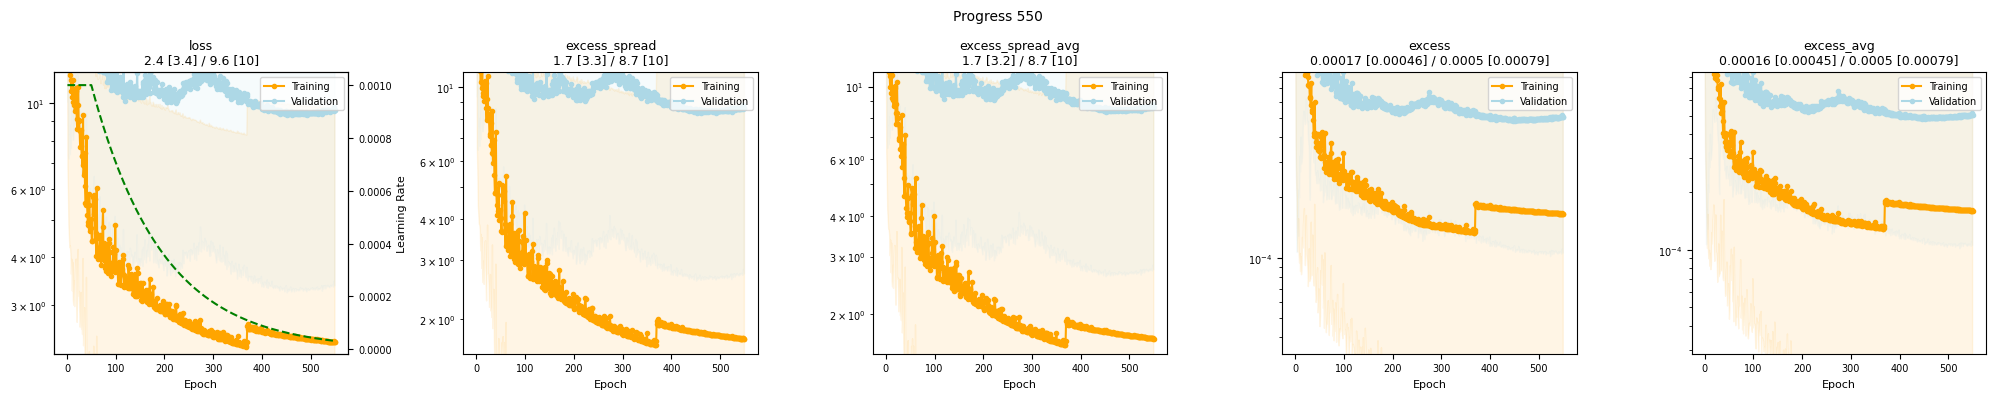

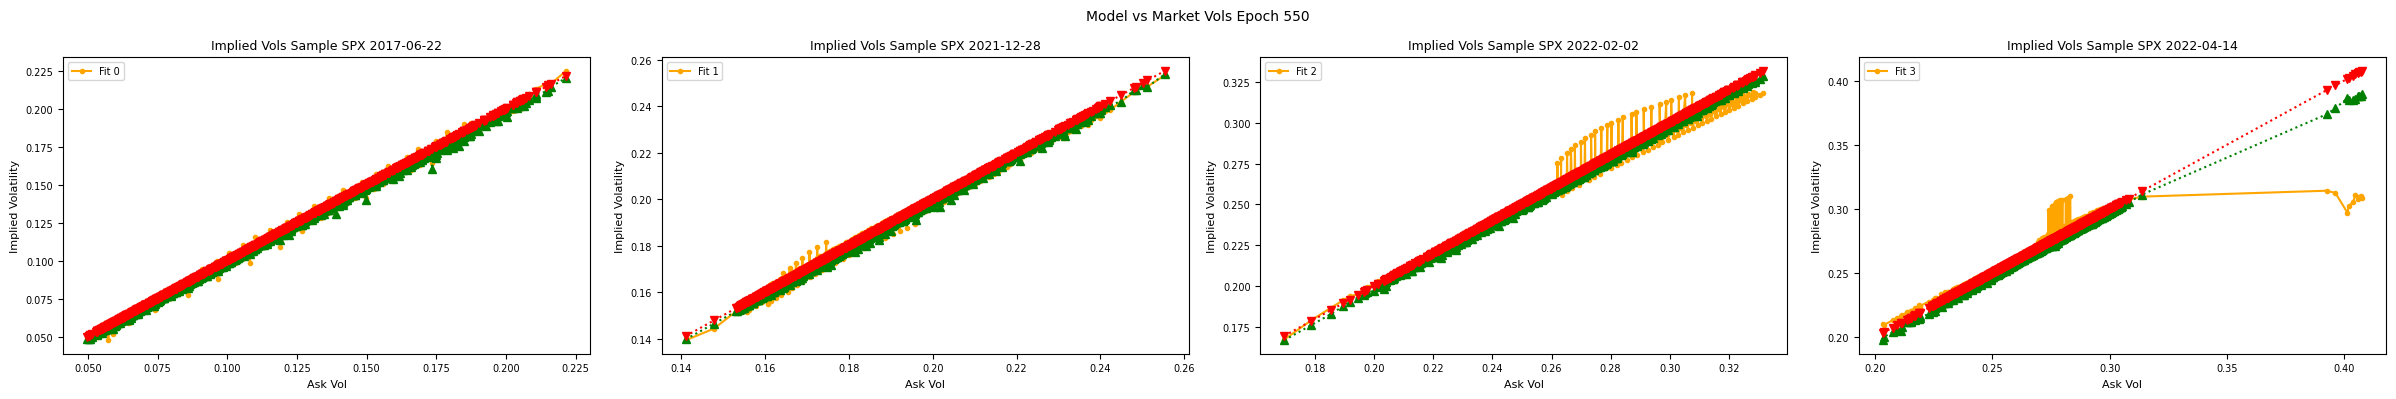

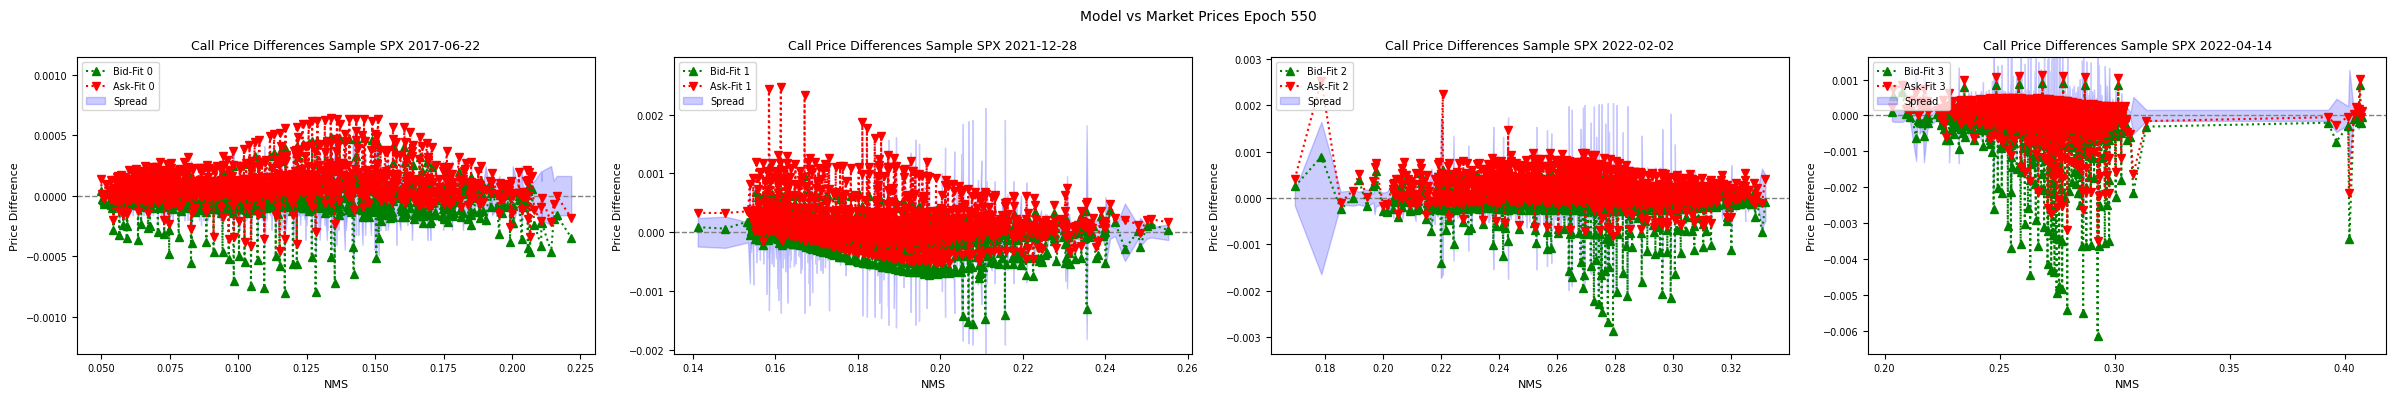

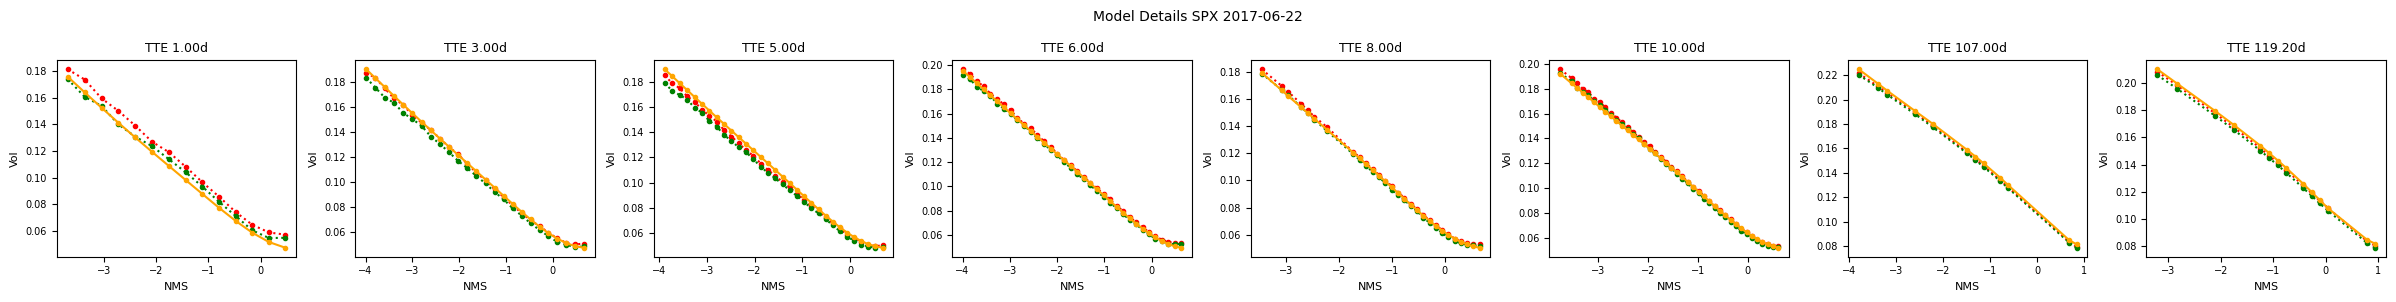

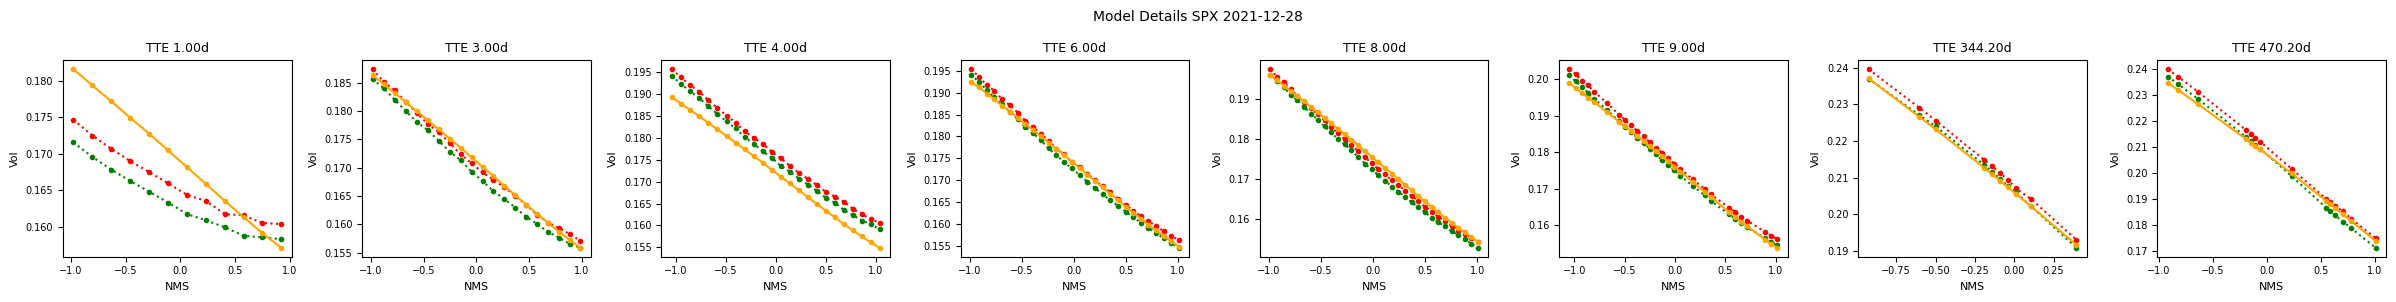

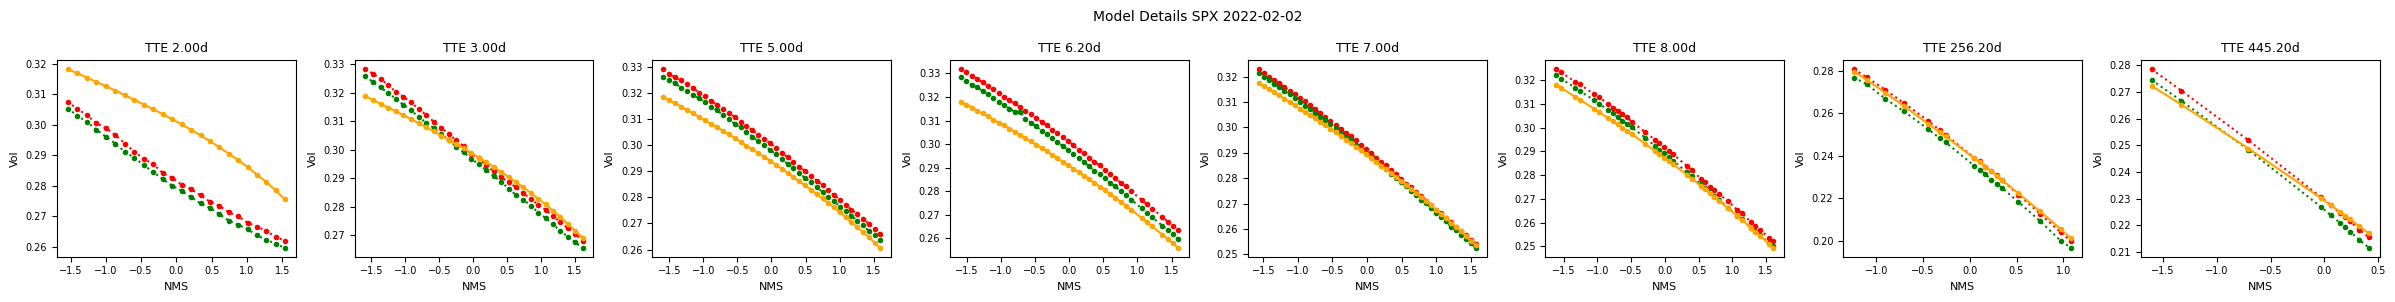

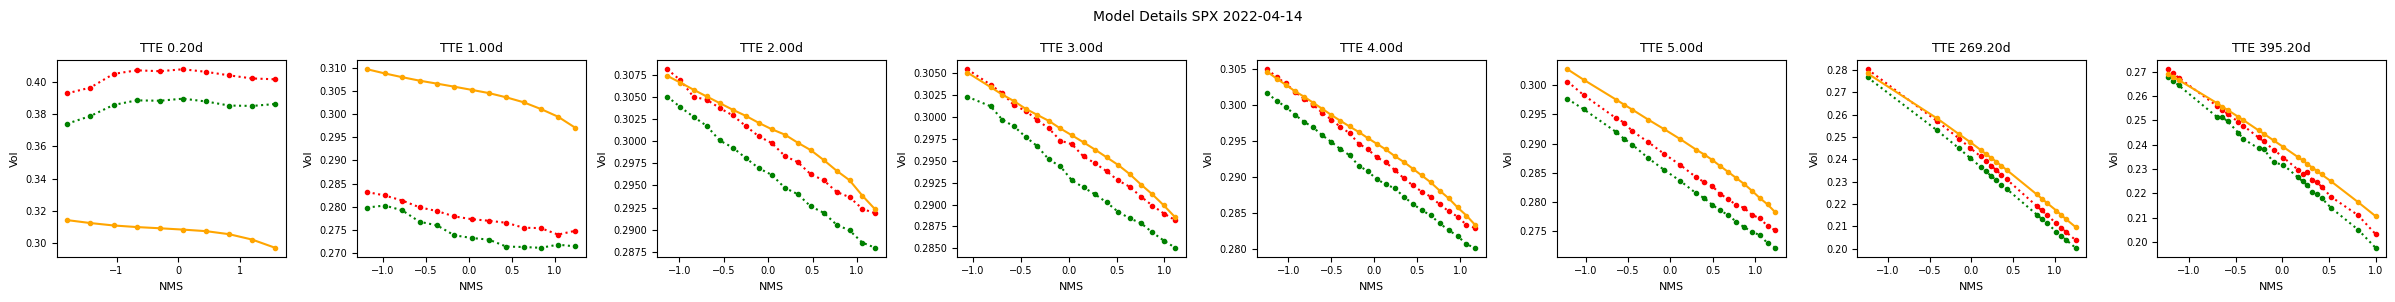

00: Training 'train_vol_vol_attin-big' epoch 371/1000 error avg trn 2.39; val 2.613/10.08 [2:22 1.1s 0.29s]. LR: 1.09e-04, GN 8.591, excess_weighted: 0.0001347/0.0004394, excess_weighted_avg: 0.0001505/0.0004787, excess_spread: 1.933/9.108, excess_spread_avg: 1.866/9.108, excess: 0.0001806/0.0005181, excess_avg: 0.0001746/0.0005181. ETA: 25:53:16.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/last.pt... done; this took 7.3ms.
00: Training 'train_vol_vol_attin-big' epoch 372/1000 error avg trn 2.495; val 2.677/9.968 [3:33 1.1s 0.29s]. LR: 1.08e-04, GN 43.47, excess_weighted: 0.0001391/0.0004341, excess_weighted_avg: 0.0001564/0.000475, excess_spread: 1.996/8.998, excess_spread_avg: 1.926/8.998, excess: 0.0001872/0.0005114, excess_avg: 0.0001808/0.0005114. ETA: 38:50:46.
01:   Epoch 372: Saving new best validation loss 9.968 vs. 10.05 at epoch 223 to '/media/storage/quantdata/experiments/dysanos/simple/

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



00: Training 'train_vol_vol_attin-big' epoch 479/1000 error avg trn 2.302; val 2.477/9.515 [2:10:29 1.1s 0.29s]. LR: 5.16e-05, GN 16.43, excess_weighted: 0.0001255/0.0004124, excess_weighted_avg: 0.000138/0.0004582, excess_spread: 1.802/8.549, excess_spread_avg: 1.738/8.549, excess: 0.0001715/0.0004947, excess_avg: 0.0001656/0.0004947. ETA: 1186:35:16.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 37aa408e/last.pt... done; this took 0.023s.
00: Training 'train_vol_vol_attin-big' epoch 480/1000 error avg trn 2.29; val 2.469/9.446 [2:11:40 1.1s 0.29s]. LR: 5.13e-05, GN 23.6, excess_weighted: 0.0001252/0.0004093, excess_weighted_avg: 0.0001376/0.0004547, excess_spread: 1.796/8.484, excess_spread_avg: 1.733/8.484, excess: 0.0001709/0.0004911, excess_avg: 0.0001651/0.0004911. ETA: 1195:04:27.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_attin-big 3

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 128,
    fit_average = True,

    encoder = AttentionPoolingEncoderFactory(
        num_head = 128,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    ),)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )
